In [2]:
#Job Market & Salary Analysis

##Objective
#Analyze job postings to understand:
#-job demand
#-salary patterns 
#-In-demand skills
#-Experience levels 
#-work arrangements
#-Geographic hiring trends


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
df = pd.read_csv("D:/JobMarketAnalysis/data/raw_jobs.csv")

In [26]:
df.head()

,posting_id,posted_on,title,seniority,city,country,remote,salary_min_usd,salary_max_usd,company_size,skills
0,J70781,2023-01-01,Junior Data Analyst,junior,New York,US,remote,65000.0,86500.0,midmarket,looker|excel|statistics|tableau|sql
1,J72149,2023-01-01,Data Analyst,mid,Chicago,US,hybrid,76500.0,102000.0,scaleup,statistics|looker|excel|python|tableau
2,J72672,2023-01-01,Analytics Engineer,mid,London,GB,remote,NaN,NaN,midmarket,python|dbt|airflow
3,J73484,2023-01-01,Senior Machine Learning Engineer,senior,Bengaluru,IN,onsite,58500.0,78000.0,scaleup,python|aws|sql|pytorch
4,J70384,2023-01-02,Junior BI Developer,junior,San Francisco,US,remote,74500.0,99500.0,midmarket,modelling|power bi|sql|excel|dax


In [27]:
df.shape
df.columns
df.info()
df.describe()
df.isnull().sum()


<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   posting_id      3500 non-null   str    
 1   posted_on       3500 non-null   str    
 2   title           3500 non-null   str    
 3   seniority       3500 non-null   str    
 4   city            3500 non-null   str    
 5   country         3500 non-null   str    
 6   remote          3500 non-null   str    
 7   salary_min_usd  2738 non-null   float64
 8   salary_max_usd  2738 non-null   float64
 9   company_size    3500 non-null   str    
 10  skills          3500 non-null   str    
dtypes: float64(2), str(9)
memory usage: 300.9 KB


posting_id          0
posted_on           0
title               0
seniority           0
city                0
country             0
remote              0
salary_min_usd    762
salary_max_usd    762
company_size        0
skills              0
dtype: int64

In [28]:
df.isnull().sum()

posting_id          0
posted_on           0
title               0
seniority           0
city                0
country             0
remote              0
salary_min_usd    762
salary_max_usd    762
company_size        0
skills              0
dtype: int64

In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df.dtypes

posting_id            str
posted_on             str
title                 str
seniority             str
city                  str
country               str
remote                str
salary_min_usd    float64
salary_max_usd    float64
company_size          str
skills                str
dtype: object

In [31]:
df["posted_on"]=pd.to_datetime(df["posted_on"])

In [32]:
df.dtypes

posting_id                   str
posted_on         datetime64[us]
title                        str
seniority                    str
city                         str
country                      str
remote                       str
salary_min_usd           float64
salary_max_usd           float64
company_size                 str
skills                       str
dtype: object

In [33]:
df[["salary_min_usd","salary_max_usd"]].describe()

,salary_min_usd,salary_max_usd
count,2738.000000,2738.000000
mean,104106.281958,138806.975895
std,50769.146511,67697.145049
min,17000.000000,22500.000000
25%,66500.000000,89000.000000
50%,98000.000000,131000.000000
75%,133500.000000,178000.000000
max,307000.000000,409000.000000


In [34]:
df["avg_salary_usd"]=(df["salary_min_usd"]+df["salary_max_usd"])/2

In [35]:
df[[
    "salary_min_usd",
    "salary_max_usd",
    "avg_salary_usd"
]].head(10)

,salary_min_usd,salary_max_usd,avg_salary_usd
0,65000.0,86500.0,75750.0
1,76500.0,102000.0,89250.0
2,NaN,NaN,NaN
3,58500.0,78000.0,68250.0
4,74500.0,99500.0,87000.0
5,76500.0,102000.0,89250.0
6,66500.0,89000.0,77750.0
7,NaN,NaN,NaN
8,NaN,NaN,NaN
9,86500.0,115500.0,101000.0


In [36]:
df["salary_available"]=df["avg_salary_usd"].notna()

In [37]:
df["salary_available"].value_counts()

salary_available
True     2738
False     762
Name: count, dtype: int64

In [38]:
df["title"].value_counts().head(10)

title
Data Analyst                 307
Senior Data Analyst          270
Data Engineer                252
Junior Data Analyst          206
Senior Data Engineer         198
Data Scientist               182
Senior Data Scientist        169
Junior Data Engineer         144
Senior Analytics Engineer    136
Analytics Engineer           131
Name: count, dtype: int64

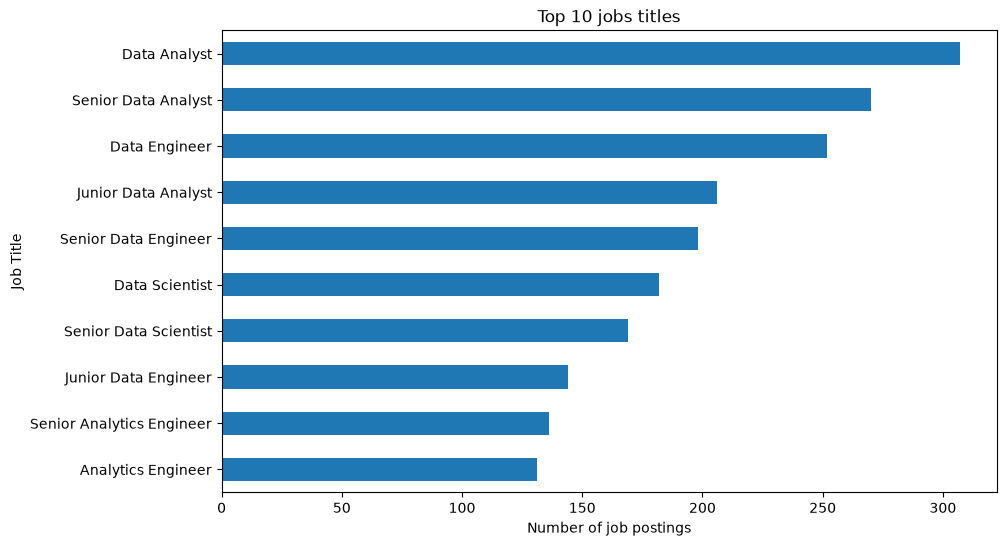

In [39]:
top_jobs=df["title"].value_counts().head(10)
plt.figure(figsize=(10,6))
top_jobs.sort_values().plot(kind="barh")

plt.title("Top 10 jobs titles")
plt.xlabel("Number of job postings")
plt.ylabel("Job Title")
plt.show()

In [40]:
df["city"].value_counts().head(10)

city
San Francisco    532
New York         495
London           436
Bengaluru        417
Berlin           333
Chicago          299
Austin           253
Toronto          247
Amsterdam        245
São Paulo        243
Name: count, dtype: int64

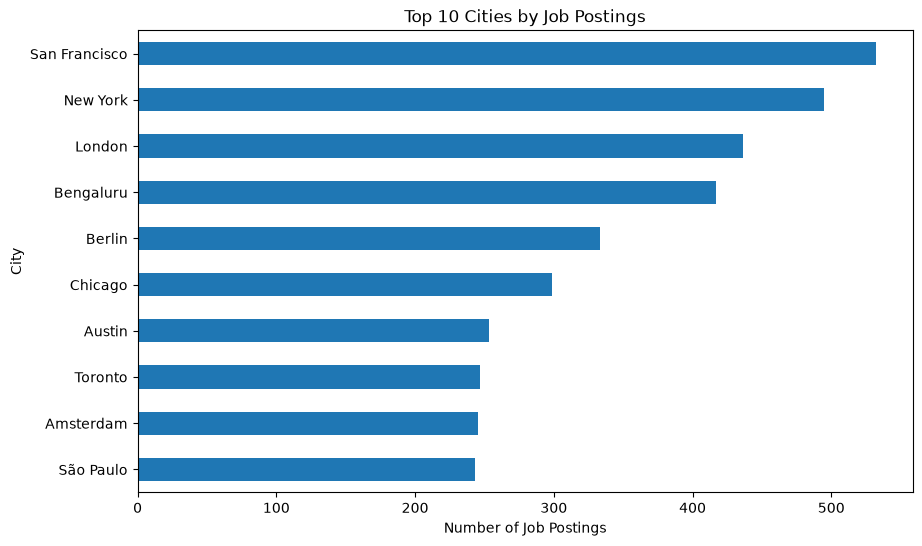

In [41]:
top_cities = df["city"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_cities.sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("City")

plt.show()

In [42]:
df["seniority"].value_counts()

seniority
mid       1170
senior     984
junior     764
staff      339
lead       243
Name: count, dtype: int64

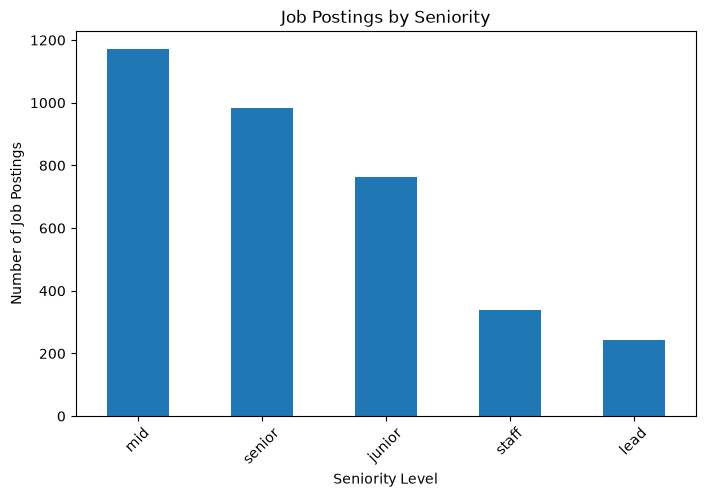

In [43]:
plt.figure(figsize=(8, 5))

df["seniority"].value_counts().plot(kind="bar")

plt.title("Job Postings by Seniority")
plt.xlabel("Seniority Level")
plt.ylabel("Number of Job Postings")

plt.xticks(rotation=45)

plt.show()

In [44]:
salary_df=df[df["salary_available"]==True].copy()

In [45]:
salary_df["avg_salary_usd"].describe()

count      2738.000000
mean     121456.628926
std       59233.050102
min       19750.000000
25%       77750.000000
50%      114500.000000
75%      155750.000000
max      358000.000000
Name: avg_salary_usd, dtype: float64

In [52]:
salary_by_seniority=(
    salary_df.groupby("seniority")["avg_salary_usd"].mean().sort_values(ascending=False))
salary_by_seniority

seniority
lead      192886.243386
staff     167052.777778
senior    134494.785276
mid       105844.528711
junior     80740.757856
Name: avg_salary_usd, dtype: float64

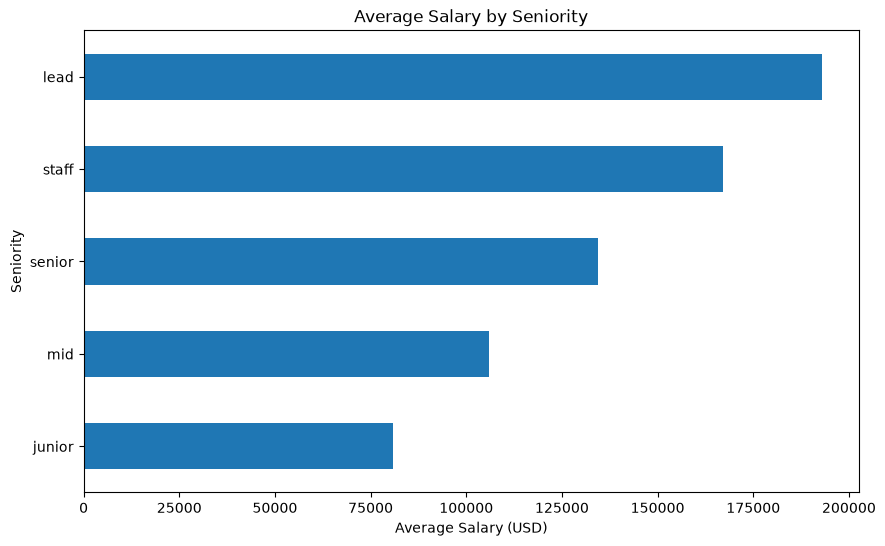

In [53]:
plt.figure(figsize=(10, 6))

salary_by_seniority.sort_values().plot(kind="barh")

plt.title("Average Salary by Seniority")
plt.xlabel("Average Salary (USD)")
plt.ylabel("Seniority")

plt.show()

In [54]:
salary_by_title = (
    salary_df.groupby("title")["avg_salary_usd"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

salary_by_title.head(10)

,mean,count
title,,
Lead Research Scientist,265343.750000,8
Lead Machine Learning Engineer,255416.666667,27
Staff Research Scientist,231321.428571,7
Staff Machine Learning Engineer,229488.636364,22
Lead Data Platform Engineer,213600.000000,15
Lead Data Scientist,207910.000000,25
Staff Data Scientist,205635.135135,37
Lead Data Engineer,202202.380952,42
Staff Data Platform Engineer,198897.727273,22


In [55]:
salary_by_title = (
    salary_df.groupby("title")["avg_salary_usd"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

salary_by_title.head(10)

,mean,count
title,,
Lead Research Scientist,265343.750000,8
Lead Machine Learning Engineer,255416.666667,27
Staff Research Scientist,231321.428571,7
Staff Machine Learning Engineer,229488.636364,22
Lead Data Platform Engineer,213600.000000,15
Lead Data Scientist,207910.000000,25
Staff Data Scientist,205635.135135,37
Lead Data Engineer,202202.380952,42
Staff Data Platform Engineer,198897.727273,22


In [56]:
salary_by_title = (
    salary_df.groupby("title")["avg_salary_usd"]
    .agg(["mean", "count"])
)

salary_by_title = salary_by_title[
    salary_by_title["count"] >= 10
].sort_values("mean", ascending=False)

salary_by_title.head(10)

,mean,count
title,,
Lead Machine Learning Engineer,255416.666667,27
Staff Machine Learning Engineer,229488.636364,22
Lead Data Platform Engineer,213600.000000,15
Lead Data Scientist,207910.000000,25
Staff Data Scientist,205635.135135,37
Lead Data Engineer,202202.380952,42
Staff Data Platform Engineer,198897.727273,22
Staff Data Engineer,175820.652174,46
Lead Analytics Engineer,175694.444444,18


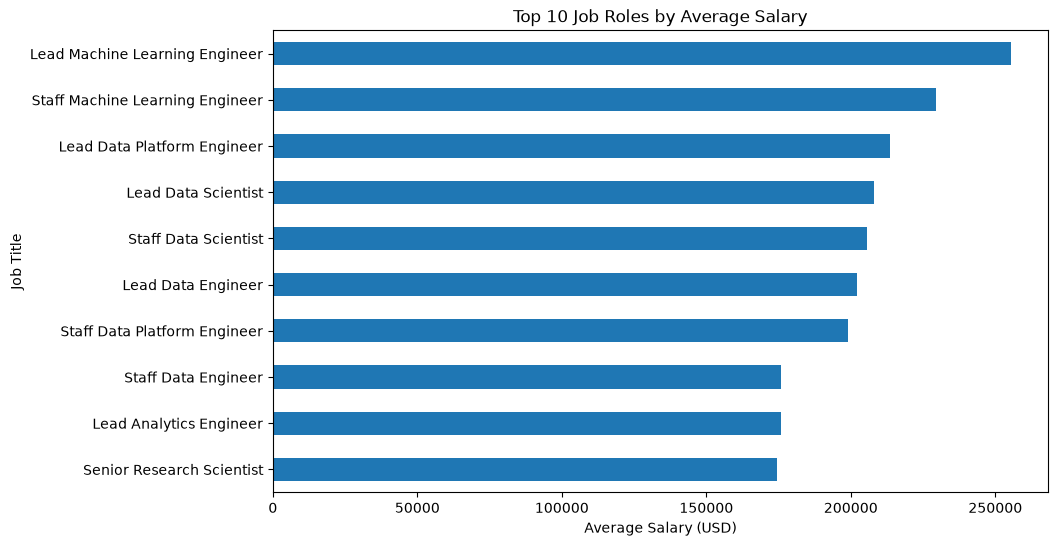

In [57]:
top_paying_roles = salary_by_title.head(10)

plt.figure(figsize=(10, 6))

top_paying_roles["mean"].sort_values().plot(kind="barh")

plt.title("Top 10 Job Roles by Average Salary")
plt.xlabel("Average Salary (USD)")
plt.ylabel("Job Title")

plt.show()

In [58]:
salary_by_city = (
    salary_df.groupby("city")["avg_salary_usd"]
    .agg(["mean", "count"])
)
salary_by_city = salary_by_city[
    salary_by_city["count"] >= 10
].sort_values("mean", ascending=False)

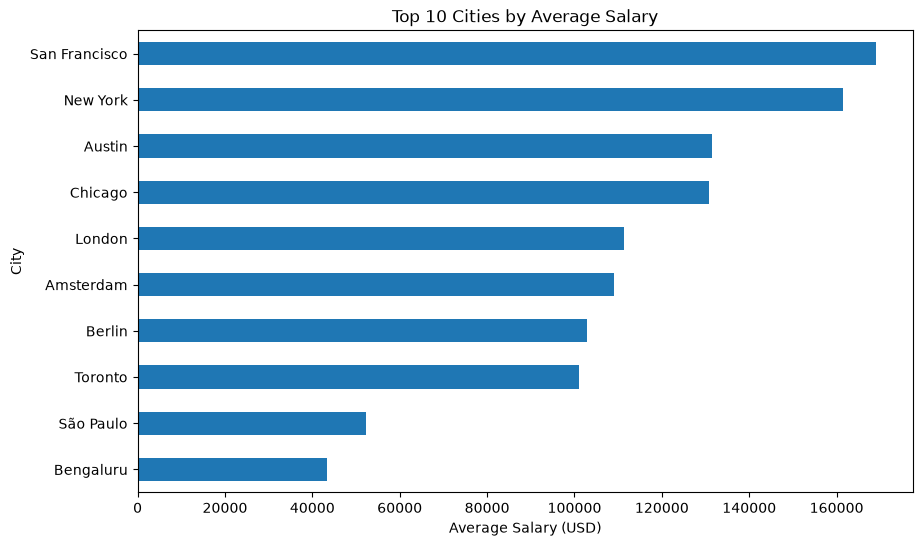

In [59]:
top_salary_cities = salary_by_city.head(10)

plt.figure(figsize=(10, 6))

top_salary_cities["mean"].sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Average Salary")
plt.xlabel("Average Salary (USD)")
plt.ylabel("City")

plt.show()

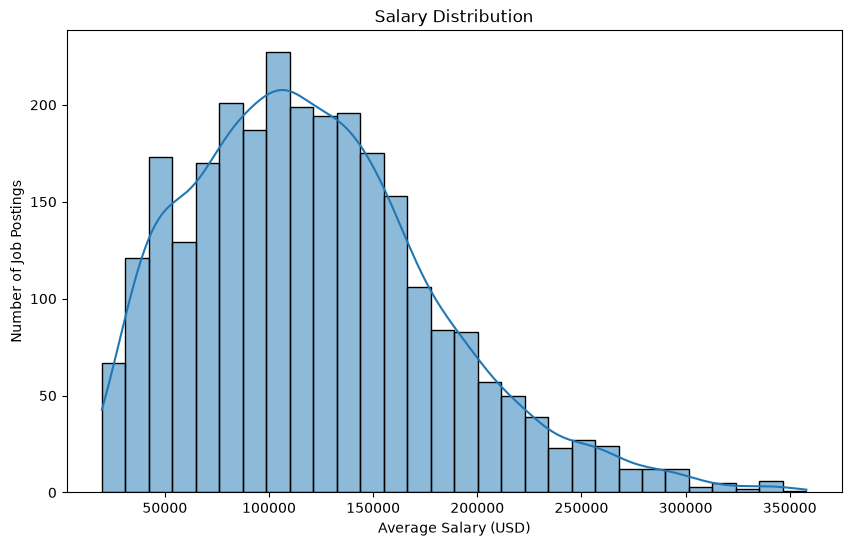

In [60]:
plt.figure(figsize=(10, 6))

sns.histplot(
    salary_df["avg_salary_usd"],
    bins=30,
    kde=True
)

plt.title("Salary Distribution")
plt.xlabel("Average Salary (USD)")
plt.ylabel("Number of Job Postings")

plt.show()

In [61]:
df.to_csv("../data/cleaned_jobs.csv", index=False)

In [62]:
cleaned_df = pd.read_csv("../data/cleaned_jobs.csv")

cleaned_df.head()

,posting_id,posted_on,title,seniority,city,country,remote,salary_min_usd,salary_max_usd,company_size,skills,avg_salary_usd,salary_available
0,J70781,2023-01-01,Junior Data Analyst,junior,New York,US,remote,65000.0,86500.0,midmarket,looker|excel|statistics|tableau|sql,75750.0,True
1,J72149,2023-01-01,Data Analyst,mid,Chicago,US,hybrid,76500.0,102000.0,scaleup,statistics|looker|excel|python|tableau,89250.0,True
2,J72672,2023-01-01,Analytics Engineer,mid,London,GB,remote,NaN,NaN,midmarket,python|dbt|airflow,NaN,False
3,J73484,2023-01-01,Senior Machine Learning Engineer,senior,Bengaluru,IN,onsite,58500.0,78000.0,scaleup,python|aws|sql|pytorch,68250.0,True
4,J70384,2023-01-02,Junior BI Developer,junior,San Francisco,US,remote,74500.0,99500.0,midmarket,modelling|power bi|sql|excel|dax,87000.0,True
